<a href="https://colab.research.google.com/github/leog89/neural_nets/blob/main/Projet_Gauthier_Leo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet 2025 - 2026 : Réseaux de neurones

In [ ]:
# Importation des modules
import torch
import matplotlib.pyplot as plt
import numpy as np

# Pour la première partie
from datasets import load_dataset
from transformers import BertTokenizer, BertModel

# Pour l'implémentation
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, random_split, Subset
import torch.nn.functional as F

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Utilisation du device : {device}")

Utilisation du device : cuda


In [ ]:
# Nettoyage du GPU au cas où

device = 'cuda'
import torch, gc
import os
gc.collect()
torch.cuda.empty_cache()

##  I. Préparation des données et tokenization

On commence par importer le jeu de données `ag_news`. On se restreint à $10\%$ de l'ensemble d'entraînement.

Le jeu de données `ag_news` est un jeu de classification de textes issues de la presse,composé de titres et descriptions de presses.

In [ ]:
# Importation de ag_news
ag_news = load_dataset("ag_news", split="train[:10%]")

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/18.6M [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/1.23M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

On affiche un bout du jeu de données pour comprendre sa structure :

In [ ]:
print(ag_news.shape)
print(ag_news)
print(ag_news[0])

(12000, 2)
Dataset({
    features: ['text', 'label'],
    num_rows: 12000
})
{'text': "Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\\band of ultra-cynics, are seeing green again.", 'label': 2}


Le jeu de données est donc composé de deux éléments : une chaîne de caractères et un label. Le label fait référence au type d'article (1 : World, 2 : Sport, 3 : Business, 4 : Sci/Tech).

### Tokenization et padding

On importe maintenant le tokenizer officiel `bert-base-uncased` :

In [ ]:
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

On doit désormais implémenter une fonction de padding pour obtenir des séquences de taille uniforme, ici $256$ caractères.

In [ ]:
def tokenize_fn(example):
    return tokenizer(example["text"], truncation=True, padding="max_length", max_length=256)

Concrètement, le tokenizer va segmenter le texte et le transformer en token. Il doit ajouter également le token spécial `CLS`au début de chaque séquence, c'est indispensable pour la tâche finale de classification.

On applique cette fonction de padding au jeu de données

In [ ]:
tokenized_dataset = ag_news.map(tokenize_fn, batched=True)

Map:   0%|          | 0/12000 [00:00<?, ? examples/s]

In [ ]:
print(tokenized_dataset)
print(tokenized_dataset.shape)

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 12000
})
(12000, 5)


Il est  important de vérifier que le token ajouté en début de séquence soit  bien `CLS`. On vérifie avant l'identifiant de tous les tokens spéciaux.

In [ ]:
print("PAD ID :", tokenizer.pad_token_id, "CLS ID :", tokenizer.cls_token_id,"MASK ID :", tokenizer.mask_token_id,"SEP ID :", tokenizer.sep_token_id, "UNK ID :", tokenizer.unk_token_id)

PAD ID : 0 CLS ID : 101 MASK ID : 103 SEP ID : 102 UNK ID : 100


In [ ]:
tokenized_dataset['input_ids'][0][0]

101

Le premier token est bien `101`, qui est l'id du token `CLS`.
Continuons et créeons le Masked Language Modeling

### Masked Language Modeling

Les Masked Language Modeling servent à prédire le token masqué dans une séquence, en prenant en compte ce qu'il se passe avant et après. Cela permet au modèle d'avoir un contexte pour le mot et de faire sa prédiction avec celui-ci.

Pour l'implémentation du Masked Language Modeling, je m'inspire de ce qui a été fait [ici](https://nn.labml.ai/transformers/mlm/index.html) en l'adaptant aux consignes.

On créée donc une classe qui gère ce MLM. On doit fournir un tenseur correspondant à une phrase (typiquement les objets `tokenized_dataset['input_ids']`), masquer 15% de ses tokens (de manière aléatoire), et produire deux tenseurs : `input_ids` (qui contient le tenseur d'entrée masqué) et un tenseur `labels` (qui contient justement uniquement ces tokens masqués, et prend la valeur $-100$ pour tous les autres tokens).

Il faudra cependant faire attention à ne pas masquer les tokens spéciaux (surtout le `PAD`), qui sont présents dans le vocabulaire pour gérer des cas particuliers.

In [ ]:
class MLM:
    def __init__(self, mask_token_id, no_mask_tokens_id, masking_prob):
        self.mask_token = mask_token_id
        self.no_mask_tokens = no_mask_tokens_id
        self.masking_prob = masking_prob

    def __call__(self, x):
        device = x.device

        # On définit le masque
        mask = torch.rand(x.shape, device=device) < self.masking_prob
        # Cette ligne précédent va sélectionner aléatoirement 15% des éléments présents dans le tenseur d'entrée et leurs assigner un booléen,
        # Elle va choisir un nombre aléatoire entre 0 et 1, s'il est < 0.15 (ce qui a 15% de chance d'arriver) => True

        # Il ne faut pas masquer les tokens spéciaux
        for t in self.no_mask_tokens:
            mask &= x != t

        labels = x.clone() # on clone le tenseur d'entrée
        labels[~mask] = -100  # on remplace par -100 les tokens non masqué

        input_ids = x.clone() # on clone le tenseur d'entrée
        input_ids[mask] = self.mask_token # on masque les tokens tels quel input_ids[mask] = True
        return input_ids, labels

In [ ]:
mask_token_id = tokenizer.mask_token_id
no_mask_tokens_id = [tokenizer.sep_token_id, tokenizer.pad_token_id, tokenizer.cls_token_id, tokenizer.unk_token_id]
masking_prob = 0.15

my_mlm = MLM(mask_token_id = mask_token_id, no_mask_tokens_id= no_mask_tokens_id, masking_prob=masking_prob)

On créé maintenant la fonction `collate_fn` qui interviendra dans la construction des batchs, et qui va passer chaque `input_ids` dans le MLM définit précédemment. On y ajoute également le masque d'attention pour ne pas considérer les caractères `PAD` :

In [ ]:
def collate_fn(batch):
    # On récupère les IDs et on les stack dans un vecteur
    input_ids_list = [torch.tensor(item["input_ids"], dtype=torch.long) for item in batch]
    inputs = torch.stack(input_ids_list)
    # On crée le masque d'attention
    attention_mask = (inputs != tokenizer.pad_token_id).long()
    # On passe les IDs dans le MLM
    inputs_id, labels = my_mlm(inputs)

    return inputs_id, labels, attention_mask

On prépare finalement les batchs

In [ ]:
train_loader = DataLoader(tokenized_dataset, batch_size=16, collate_fn = collate_fn, shuffle=True)

In [ ]:
batch = next(iter(train_loader))
print(batch[0].shape)
print(batch[1].shape)
print(batch[2].shape)


torch.Size([16, 256])
torch.Size([16, 256])
torch.Size([16, 256])


## II. Architecture du modèle

On passe maintenant à la création de l'architecture de notre modèle BERT.


On dispose de $d_{\text{model}} = 128$, $4$ couches de transformers avec chacune $4$ têtes d'attention.

In [ ]:
vocab_size = tokenizer.vocab_size
d_model = 128
nhead = 4
num_layers = 4

### Positonal Embedding

En cours, on a vu un exemple de positonal embedding sinusoïdal. J'ai donc voulu commencer par implémenter celui-ci. Malheureusement, j'ai vite rencontré des incohérences dans les prédictions faites. Il s'est avéré qu'un problème majeur de cette méthode est que les tokens de position ne sont pas "apprenables", ce qui limite les performances du modèle.

On ajoute une couche de normalisation, qui d'après Internet (par exemple [ici](https://www.geeksforgeeks.org/deep-learning/what-is-layer-normalization/)) permet de réduire le temps de calcul et rend les prédictions plus stables.

In [ ]:
class BERTEmbeddings(nn.Module):
    def __init__(self, vocab_size, d_model, max_length=256, dropout=0.1):
        super().__init__()
        self.token_embedding = nn.Embedding(vocab_size, d_model)
        self.position_embedding = nn.Embedding(max_length, d_model)
        self.layer_norm = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input_ids):
        seq_length = input_ids.size(1)

        # On encode l'ordre des mots
        position_ids = torch.arange(seq_length, device=input_ids.device)
        position_ids = position_ids.unsqueeze(0).expand_as(input_ids)

        # Embeddings
        token_embeds = self.token_embedding(input_ids)
        position_embeds = self.position_embedding(position_ids)

        # Addition
        embeddings = token_embeds + position_embeds
        # Normalisation
        embeddings = self.layer_norm(embeddings)
        embeddings = self.dropout(embeddings)

        return embeddings

### MiniBERT

On implémente MiniBERT, un module qui contient l'Embedding défini précédemment, puis l'Encoder avec 4 couches de Transformers et 4 têtes d'attention.

In [ ]:
class MiniBERT(nn.Module):
    def __init__(self, vocab_size, d_model, nhead, num_layers, dropout=0.1, max_len=256):
        super().__init__()

        self.d_model = d_model
        # On applique l'embedding
        self.embedding = BERTEmbeddings(vocab_size, d_model, max_len, dropout)
        # On crée le transfomer à 4 couches :
        encoder_layer = nn.TransformerEncoderLayer(d_model=d_model, nhead=nhead, batch_first=True, dropout=dropout)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers)

    def forward(self, x, attention_mask=None):
        if attention_mask is not None:
            # True = positions à ignorer
            key_padding_mask = attention_mask == 0
        else:
            key_padding_mask = None

        emb = self.embedding(x)
        output = self.encoder(emb, src_key_padding_mask=key_padding_mask)
        return output

In [ ]:
mini_bert = MiniBERT(vocab_size=vocab_size, d_model=d_model, nhead=nhead, num_layers=num_layers)

### BERTPretrain

Enfin, on encapsule le tout dans un module `BERTPretrain`, qui passe les résultats de `MiniBERT` dans une couche linéaire de sortie vers la dimension du vocabulaire.

In [ ]:
class BERTPretrain(nn.Module):
    def __init__(self, minibert: MiniBERT, vocab_size):
        super().__init__()
        self.minibert = minibert
        self.fc_out = nn.Linear(minibert.d_model, vocab_size)

    def forward(self, x, attention_mask=None):
        output = self.minibert(x, attention_mask=attention_mask)
        # On passe les outputs de minibert dans une couche linéaire
        outputs = self.fc_out(output)
        return outputs

In [ ]:
bert_pretrain = BERTPretrain(minibert=mini_bert, vocab_size=vocab_size)

## III. Boucle de pré-entraînement

Pour ignorer certaines valeurs des inputs, on utilise l'argument `ignore_index`. On adapte le code qu'on a utilisé dans le TP 5 avec une fonction d'entraînement. Ce code nous permettait d'enregistrer l'évolution de la loss, qui permettra d'évaluer la convergence de celle-ci dans un prochain temps, et peut également être réutilisable.

In [ ]:
bert_pretrain = bert_pretrain.to(device)

def train_bert():
    bert_pretrain.train()
    optimizer = torch.optim.AdamW(bert_pretrain.parameters(), lr=5e-4)
    loss_function = torch.nn.CrossEntropyLoss(ignore_index=-100)
    epoch_losses = []
    num_epochs = 45

    for epoch in range(num_epochs):
        tot_loss = 0
        num_batches = 0

        for input_ids, labels, attention_mask in train_loader:
            input_ids = input_ids.to(device)
            labels = labels.to(device)
            attention_mask = attention_mask.to(device)

            optimizer.zero_grad()
            outputs = bert_pretrain(input_ids, attention_mask)

            loss = loss_function(outputs.reshape(-1, outputs.size(-1)), labels.reshape(-1))

            loss.backward()
            optimizer.step()

            tot_loss += loss.item()
            num_batches += 1

        avg_loss = tot_loss / num_batches
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss:.4f}")
        epoch_losses.append(avg_loss)

    return epoch_losses

In [ ]:
losses = train_bert()

Epoch 1/45, Loss: 7.5916
Epoch 2/45, Loss: 7.2468
Epoch 3/45, Loss: 7.1224
Epoch 4/45, Loss: 7.0095
Epoch 5/45, Loss: 6.9178
Epoch 6/45, Loss: 6.8458
Epoch 7/45, Loss: 6.7829
Epoch 8/45, Loss: 6.7101
Epoch 9/45, Loss: 6.6584
Epoch 10/45, Loss: 6.5571
Epoch 11/45, Loss: 6.5051
Epoch 12/45, Loss: 6.4552
Epoch 13/45, Loss: 6.3716
Epoch 14/45, Loss: 6.3112
Epoch 15/45, Loss: 6.2242
Epoch 16/45, Loss: 6.1959
Epoch 17/45, Loss: 6.1411
Epoch 18/45, Loss: 6.0652
Epoch 19/45, Loss: 6.0095
Epoch 20/45, Loss: 5.9472
Epoch 21/45, Loss: 5.8679
Epoch 22/45, Loss: 5.8303
Epoch 23/45, Loss: 5.7765
Epoch 24/45, Loss: 5.7142
Epoch 25/45, Loss: 5.6587
Epoch 26/45, Loss: 5.6228
Epoch 27/45, Loss: 5.5733
Epoch 28/45, Loss: 5.5324
Epoch 29/45, Loss: 5.4698
Epoch 30/45, Loss: 5.4380
Epoch 31/45, Loss: 5.3912
Epoch 32/45, Loss: 5.3569
Epoch 33/45, Loss: 5.3040
Epoch 34/45, Loss: 5.2866
Epoch 35/45, Loss: 5.2307
Epoch 36/45, Loss: 5.1785
Epoch 37/45, Loss: 5.1570
Epoch 38/45, Loss: 5.1061
Epoch 39/45, Loss: 5.

On évalue désormais la convergence de la loss :

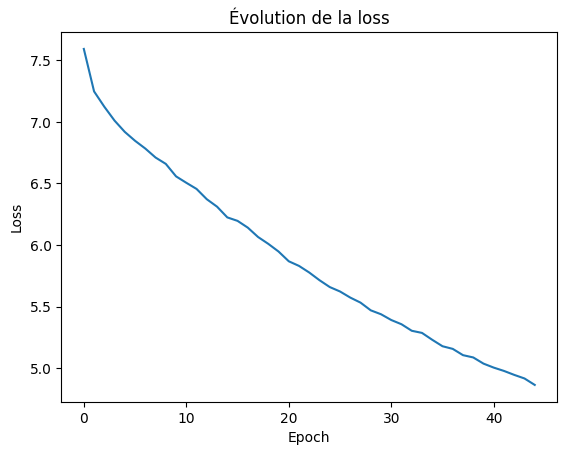

In [ ]:
plt.figure()
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Évolution de la loss")
plt.show()

On se limite à une dizaine d'epochs, mais on pourrait laisser tourner un peu plus longtemps. En effet, la loss ne semble pas encore converger.


### Test qualitatif

Pour le test qualitatif, on masque un mot dans une phrase avec du contexte (avant et après le mot masqué). On passe ensuite les sorties du modèle pré-entraîné dans la fonction $\text{Softmax}$ et on interprète les sorties de cette fonction comme les probabilités associées à chaque token.

In [ ]:
text = "The president met with the [MASK] leaders today"

tokens = tokenizer(text, return_tensors="pt", padding="max_length", truncation=True, max_length=256).to(device)
input_ids = tokens["input_ids"]
attention_mask = tokens["attention_mask"]

with torch.no_grad():
    outputs = bert_pretrain(input_ids, attention_mask=attention_mask)
    mask_idx = (input_ids[0] == tokenizer.mask_token_id).nonzero(as_tuple=True)[0]

    # On passe dans le Softmax
    probs = torch.softmax(outputs[0, mask_idx, :], dim=-1)
    top5_probs, top5_indices = torch.topk(probs.flatten(), k=5)

    print("Top-5 prédictions pour [MASK] :")
    for word, prob in zip([tokenizer.decode([int(idx)]) for idx in top5_indices], top5_probs):
        print(f"  {word}: {prob.item():.4f}")

Top-5 prédictions pour [MASK] :
  palestinian: 0.0343
  murder: 0.0303
  veterans: 0.0260
  british: 0.0155
  equatorial: 0.0142


On voit que les propositions ne sont pas toutes hors contexte, donc on peut estimer que le modèle apprend bien. En revanche, les probabilités associées à chaque mot sont faibles. Cela peut signifier que le modèle n'est pas complètement certain de ses prédictions, et que faire plus d'epochs serait une bonne chose.

Il est important de préciser que je n'ai pas utilisé de graine pour la reproductibilité des résultats. Certaines compilations proposent un mot cohérent pour le token masqué tandis que d'autres peuvent en proposer 5.

## IV. Fine-tuning pour la classification

On passe maintenant à la partie importante. On va évaluer les paramètres appris par notre modèle à l'étape III sur un nouveau jeu de données, ici `IMDB` qui contient des critiques de films. L'idée est donc de reprendre ces paramètres et d'adapter le modèle `MiniBERT` pour une tâche de classification (donc déterministe)

### Préparation du jeu de données

Le jeu de données `IMDB` contient 50 000 critiques de films, toutes classées comme étant soit positive soit négative. Il est séparé en deux parties de taille égale, une pour l'entraînement et l'autre pour le test.

On aimerait importer `IMDB`de la même manière que le jeu précédent mais il faut faire attention car les 25 000 observations du jeu d'entraînement sont ordonnées. On retrouve d'abord les reviews négatives puis les reviews positives.

In [ ]:
imdb_train = load_dataset("imdb", split="train").shuffle(seed=42).select(range(250))
imdb_test = load_dataset("imdb", split="test")

README.md: 0.00B [00:00, ?B/s]

plain_text/train-00000-of-00001.parquet:   0%|          | 0.00/21.0M [00:00<?, ?B/s]

plain_text/test-00000-of-00001.parquet:   0%|          | 0.00/20.5M [00:00<?, ?B/s]

plain_text/unsupervised-00000-of-00001.p(…):   0%|          | 0.00/42.0M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

In [ ]:
print(imdb_train.shape)
print(imdb_train[0])

(250, 2)
{'text': 'There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier\'s plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compare, to judge, to evaluate. How about just enjoying? Funny thing too, people writing Fortier looks American but, on the other hand, arguing they prefer American series (!!!). Maybe it\'s the language, or the spirit, but I think this series is more English than American. By the way, the actors are really good and funny. The acting is not superficial at all...', 'label': 1}


Il y a seulement 250 critiques disponibles pour l'entraînement du modèle, c'est peu.

Oncommence par tokenizer les jeux d'entraînement et de test.

In [ ]:
tokenized_imdb_train = imdb_train.map(tokenize_fn, batched=True)
tokenized_imdb_test = imdb_test.map(tokenize_fn, batched=True)

Map:   0%|          | 0/250 [00:00<?, ? examples/s]

Map:   0%|          | 0/25000 [00:00<?, ? examples/s]

### BERTClassifier

On crée la classe qui va adapter `MiniBERT` pour un problème de classification. C'est à dire qu'on va devoir passer le token `CLS` de l'output dans une couche de sortie linéaire vers le nombre de classes différentes potentiellement prédite.

Ce token `CLS` est conçu pour agréger l'information contenue dans dans l'ensemble des tokens de la séquence, via le mécanisme d'attention. La couche linéaire de sortie va ainsi interpréter ce token comme une représentation globale de la séquence, et sera utilisée pour le problème de classification.

In [ ]:
class BERTClassifier(nn.Module):
    def __init__(self, bert, d_model, num_classes):
        super().__init__()
        self.bert = bert
        self.classifier = nn.Linear(d_model, num_classes)

    def forward(self, input_ids, attention_mask=None):
        # output
        outputs = self.bert(input_ids, attention_mask=attention_mask)

        # On prend le vecteur du premier token [CLS]
        cls_output = outputs[:, 0, :]  # shape: (batch_size, d_model)

        # Passage dans la couche de classification
        logits = self.classifier(cls_output)
        return logits

On instancie le modèle

In [ ]:
num_classes=2

bertclassifier_imdb = BERTClassifier(bert=mini_bert,
                                      d_model=d_model,
                                      num_classes=num_classes).to(device)

On doit maintenant copier les poids de l'encodeur de `BERTPretrain` dans l'encodeur de `BERTClassifier` :

In [ ]:
bertclassifier_imdb.bert.load_state_dict(
    bert_pretrain.minibert.state_dict())

<All keys matched successfully>

### Entraînement

On passe maintenant à l'entraînement du Classifier, et on nous demande d'en évaluer l'accuracy. Avant ça, on doit préparer les batchs et un masque d'attention.

In [ ]:
def collate_fn_imdb(batch):
    input_ids = torch.stack([torch.tensor(item["input_ids"], dtype=torch.long) for item in batch])
    attention_mask = (input_ids != tokenizer.pad_token_id).long()
    labels = torch.tensor([item["label"] for item in batch], dtype=torch.long)

    return input_ids, attention_mask, labels

In [ ]:
imdb_train_loader = DataLoader(tokenized_imdb_train, batch_size=16,
                         collate_fn=collate_fn_imdb, shuffle=True)

imdb_test_loader = DataLoader(tokenized_imdb_test, batch_size=16,
                         collate_fn=collate_fn_imdb)

Dans les problèmes de classification, on n'utilise pas la fonction Softmax mais l'argmax de la sortie.

In [ ]:
def train_imdb():
  bertclassifier_imdb.train()
  optimizer = torch.optim.AdamW(bertclassifier_imdb.parameters(), lr=5e-5)
  loss_function = torch.nn.CrossEntropyLoss()  # loss pour les problèmes de classification
  epoch_losses = []
  epoch_acc = []
  num_epochs=5

  for epoch in range(num_epochs):
      tot_loss = 0
      correct = 0
      total = 0
      num_batches = 0

      for input_ids, attention_mask, labels in imdb_train_loader:
          input_ids = input_ids.to(device)
          labels = labels.to(device)
          attention_mask = attention_mask.to(device)

          optimizer.zero_grad()
          outputs = bertclassifier_imdb(input_ids, attention_mask)

          loss = loss_function(outputs, labels)
          loss.backward()
          optimizer.step()

          tot_loss += loss.item()
          num_batches += 1

          # Calcul de l'accuracy manuellement
          preds = torch.argmax(outputs, dim=-1) # Calcul de l'argmax
          correct += (preds == labels).sum().item()
          total += labels.size(0)

      avg_loss = tot_loss / num_batches
      acc = correct / total

      print(f"Epoch {epoch+1}/{num_epochs}, Loss: {avg_loss:.4f}, Accuracy: {acc:.4f}")
      epoch_losses.append(avg_loss)
      epoch_acc.append(acc)

  return epoch_losses, epoch_acc

In [ ]:
imdb_losses, imdb_train_accs = train_imdb()

Epoch 1/5, Loss: 0.7548, Accuracy: 0.4960
Epoch 2/5, Loss: 0.6910, Accuracy: 0.5320
Epoch 3/5, Loss: 0.7150, Accuracy: 0.4920
Epoch 4/5, Loss: 0.6771, Accuracy: 0.5600
Epoch 5/5, Loss: 0.6839, Accuracy: 0.5600


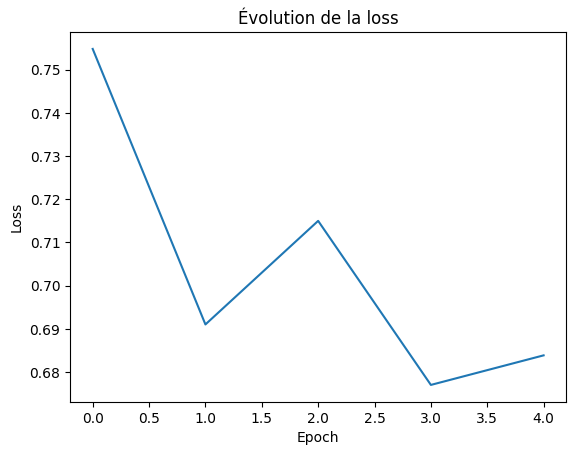

In [ ]:
plt.figure()
plt.plot(imdb_losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Évolution de la loss")
plt.show()

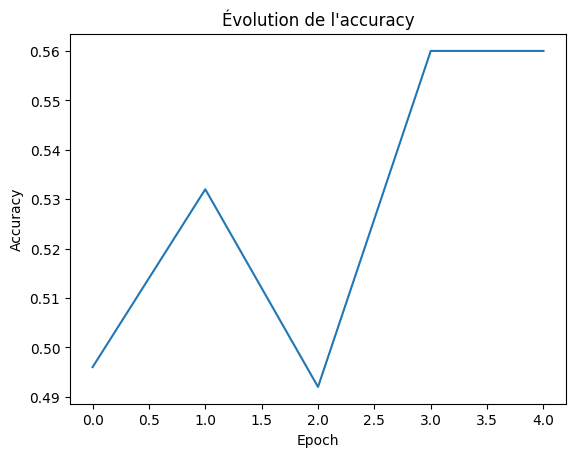

In [ ]:
plt.figure()
plt.plot(imdb_train_accs)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Évolution de l'accuracy")
plt.show()

On voit qu'on a très vite une accuracy élevée et une loss très faible. Ça n'est pas très étonnant, on a seulement $250$ observations dans le jeu d'entraînement, le modèle sur-apprend très vite. Pour vérifier si c'est bien du sur-apprentissage, on utilise le jeu de test.

### Evaluation sur l'ensemble de test

In [ ]:
def evaluate_classifier():
    bertclassifier_imdb.eval()
    epoch_losses = []
    epoch_acc = []
    correct = 0
    total = 0
    tot_loss = 0
    num_batches = 0

    loss_function = torch.nn.CrossEntropyLoss()

    with torch.no_grad():
        for input_ids, attention_mask, labels in imdb_test_loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            logits = bertclassifier_imdb(input_ids, attention_mask)

            loss = loss_function(logits, labels)
            tot_loss += loss.item()
            num_batches += 1

            preds = torch.argmax(logits, dim=1)

            correct += (preds == labels).sum().item()
            total += labels.size(0)

    acc = correct / total
    avg_loss = tot_loss / num_batches

    epoch_acc.append(acc)
    epoch_losses.append(avg_loss)

    return epoch_acc, epoch_losses

In [ ]:
test_acc, test_loss = evaluate_classifier()

print(f"Test loss :{test_loss:.4f}, Test accuracy :{test_acc:.4f}")

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/transformer.py:515: UserWarning: The PyTorch API of nested tensors is in prototype stage and will change in the near future. We recommend specifying layout=torch.jagged when constructing a nested tensor, as this layout receives active development, has better operator coverage, and works with torch.compile. (Triggered internally at /pytorch/aten/src/ATen/NestedTensorImpl.cpp:178.)
  output = torch._nested_tensor_from_mask(


Test loss :0.7017, Test accuracy :0.5133


In [ ]:
plt.figure()
plt.plot(test_loss)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Évolution de la loss")
plt.show()

NameError: name 'tes_loss' is not defined

<Figure size 640x480 with 0 Axes>

In [ ]:
plt.figure()
plt.plot(test_acc)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Évolution de l'accuracy")
plt.show()

L'accuracy obtenue sur l'ensemble de test est proche de $0.5$, soit l'équivalent d'un choix aléatoire pour une classification binaire. Cela confirme bien que le modèle ne généralise pas bien et que les bons résultats sur le jeu d'entraînement sont dues à un surapprentissage.

## V. Étude d'ablation

L'étude d'ablation qu'on implémente ici consiste à mesurer l'impact du pré-entraînement de `BERT`. Ainsi, on va entraîner un nouveau modèle "from scratch" (sans les paramètres entraînés sur `ag_news`) et on comparera les performances de classification avec celui entraîné sur `ag_news`.

### Modèle "From Scratch"

On commence par instancier le modèle from scratch :

In [ ]:
mini_bert_scratch = MiniBERT(vocab_size, d_model=d_model, nhead=nhead, num_layers=num_layers)

classifier_scratch = BERTClassifier(mini_bert_scratch, d_model=d_model, num_classes=2)

In [ ]:
classifier_scratch = classifier_scratch.to(device)

def train_scratch_classifier():
    classifier_scratch.train()

    optimizer = torch.optim.AdamW(classifier_scratch.parameters(), lr=5e-5)
    loss_function = nn.CrossEntropyLoss()

    num_epoch=5

    train_losses = []
    train_accs = []

    for epoch in range(num_epoch):

        classifier_scratch.train()
        total_loss = 0
        correct = 0
        total = 0
        num_batches = 0

        for input_ids, attention_mask, labels in imdb_train_loader:
            input_ids = input_ids.to(device)
            attention_mask = attention_mask.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()
            logits = classifier_scratch(input_ids, attention_mask)
            loss = loss_function(logits, labels)
            loss.backward()
            optimizer.step()

            total_loss += loss.item()
            num_batches += 1

            # Accuracy
            preds = torch.argmax(logits, dim=1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)

        avg_loss = total_loss / num_batches
        train_acc = correct / total

        train_losses.append(avg_loss)
        train_accs.append(train_acc)

        print(f"Epoch {epoch+1}/{num_epoch}, "f"Loss: {avg_loss:.4f}, "f"Accuracy: {train_acc:.4f}")

    return train_losses, train_accs

In [ ]:
losses_scratch, train_accs_scratch = train_scratch_classifier()

Epoch 1/5, Loss: 0.7291, Accuracy: 0.4960
Epoch 2/5, Loss: 0.6857, Accuracy: 0.5440
Epoch 3/5, Loss: 0.7219, Accuracy: 0.5240
Epoch 4/5, Loss: 0.7200, Accuracy: 0.4760
Epoch 5/5, Loss: 0.6984, Accuracy: 0.4720


### Comparaison du modèle "From Scratch" et du modèle pré-entraîné

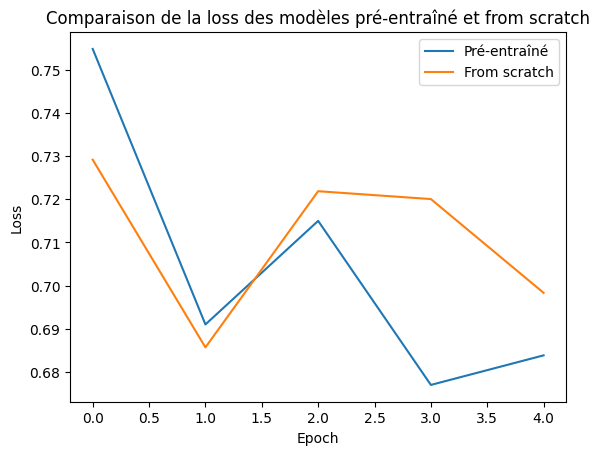

In [ ]:
plt.figure()
plt.plot(imdb_losses, label = "Pré-entraîné")
plt.plot(losses_scratch, label = "From scratch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Comparaison de la loss des modèles pré-entraîné et from scratch")
plt.legend()
plt.show()

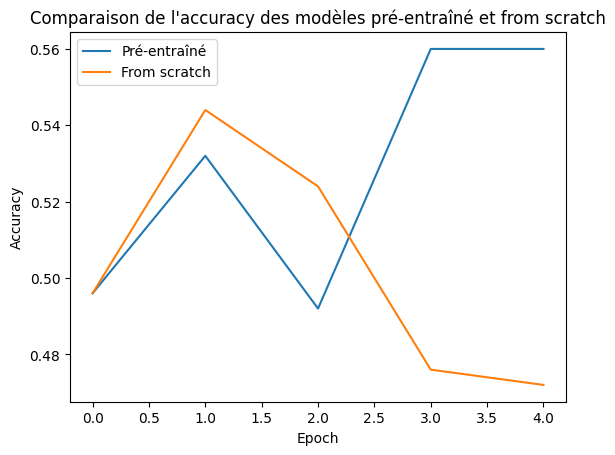

In [ ]:
plt.figure()
plt.plot(imdb_train_accs, label = "Pré-entraîné")
plt.plot(train_accs_scratch, label = "From scratch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Comparaison de l'accuracy des modèles pré-entraîné et from scratch")
plt.legend()
plt.show()

Puisque je n'ai pas implémenté de graine, les résultats varient légèrement en fonction des compilations. En général, on retrouve une loss plus élevée que dans le modèle pré-entraîné. Par contre, l'accuracy croit souvent de la même manière que dans le modèle pré-entraîné, en étant élevée très vite.

Le modèle est probablement en train de sur-apprendre. Cela peut être du à la petite taille du jeu d'entraînement. Pour vérifier cela, on va tester le modèle.

In [ ]:
def evaluate_scratch_classifier():
  classifier_scratch.eval()
  epoch_losses = []
  epoch_acc = []
  correct = 0
  total = 0
  tot_loss = 0
  num_batches = 0

  loss_function = torch.nn.CrossEntropyLoss()

  with torch.no_grad():
      for input_ids, attention_mask, labels in imdb_test_loader:
          input_ids = input_ids.to(device)
          attention_mask = attention_mask.to(device)
          labels = labels.to(device)

          logits = classifier_scratch(input_ids, attention_mask)

          loss = loss_function(logits, labels)
          tot_loss += loss.item()
          num_batches += 1

          preds = torch.argmax(logits, dim=1)

          correct += (preds == labels).sum().item()
          total += labels.size(0)

  acc = correct / total
  epoch_acc.append(acc)
  avg_loss = tot_loss / num_batches
  epoch_losses.append(avg_loss)
  return epoch_acc, epoch_losses

In [ ]:
evaluate_scratch_classifier()

([0.5654], [0.6899135236700452])

Effectivement, l'accuracy obtenue sur le jeu de test nous conforte généralement dans notre suspicion de sur-apprentissage en étant à peine meilleure que du hasard. Elle est moins bonne que celle obtenue avec les paramètres pré-entraînés

Cela est clairement du à la petite taille du jeu d'entraînement. Le modèle "from scratch" n'ayant pas d'information préalable, il se base sur ce qui est disponible dans `imdb_train` et surapprend. La perspective qu'on peut avoir ici serait d'utiliser un plus grand nombre de données d'entraînement

# Conclusion

Dans un premier temps, nous avons implémenté un modèle `BERT` qui apprends bien et propose des prédictions correctes pour les tokens masquées.

Nous avons ensuité ré-utilisé les poids de ce modèle pour un problème de classification, et nous en avons comparé les performances avec un modèle "from scratch" dans l'étude d'ablation.

On aboutit à une conclusion cohérente : un modèle pré-entraîné permet de meilleures performances sur les jeux de test. On identifie cependant la même limite à l'implémentation faite ici : on manque de données annotées pour l'entraînement de ce modèle. Ainsi, on est dans un cas de sur-apprentissage des données d'entraînement.